## Part A: Baseline

In this part, a baseline Inception-style CNN is trained from scratch on a subset of 500 CIFAR-10 training images, with 400 images used for training and 100 for validation. No data augmentation is applied. The clean and shifted test sets are reserved for final evaluation.

- **Random Seeds:** 42, 123, 2026
- **Maximum Epochs:** 60
- **Batch Size:** 32
- **Optimizer:** Adam
- **Learning Rate:** 0.001
- **Model:** Inception-style CNN with fewer than 1 million trainable parameters
- **Augmentation:** None

The best checkpoint is selected using validation accuracy. Training and validation loss and accuracy curves are plotted. Training, validation, clean-test, and shifted-test accuracies are reported as mean ± standard deviation across three runs. The difference between clean-test and shifted-test performance is briefly discussed.

In [25]:
import random
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision.transforms as T
import torchvision.transforms.functional as TF

from PIL import Image, ImageDraw, ImageOps
from torchvision.datasets import CIFAR10
from torch.utils.data import Dataset, Subset, DataLoader

SEEDS = [42, 123, 2026]
BATCH_SIZE = 32
EPOCHS = 60
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)

transform = T.Compose([
    T.ToTensor(),
    T.Normalize((0.4914, 0.4822, 0.4465),
                (0.2470, 0.2435, 0.2616))
])

# Original CIFAR-10 datasets
raw_train = CIFAR10("./data", train=True, download=True)
raw_test = CIFAR10("./data", train=False, download=True)

# train_small: exactly 50 images per class
targets = np.array(raw_train.targets)
rng = np.random.RandomState(42)
small_idx = []

for c in range(10):
    ids = np.where(targets == c)[0]
    small_idx.extend(rng.choice(ids, 50, replace=False).tolist())

train_small = Subset(raw_train, small_idx)

# Stratified split: 40 train + 10 val per class
small_labels = targets[small_idx]
train_idx, val_idx = [], []

for c in range(10):
    ids = np.where(small_labels == c)[0].tolist()
    random.Random(42 + c).shuffle(ids)
    train_idx.extend(ids[:40])
    val_idx.extend(ids[40:])

# Transformed datasets; no augmentation for baseline training
train_base = CIFAR10("./data", train=True, transform=transform)
test_base = CIFAR10("./data", train=False, transform=transform)

train = Subset(train_base, [small_idx[i] for i in train_idx])
val = Subset(train_base, [small_idx[i] for i in val_idx])
clean_test = test_base

class ShiftedCIFAR10(Dataset):
    def __init__(self, dataset, seed=2026):
        self.dataset = dataset
        self.seed = seed

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        image, label = self.dataset.data[idx], self.dataset.targets[idx]
        image = Image.fromarray(image).convert("RGB")
        rng = np.random.default_rng(self.seed + idx)
        py_rng = random.Random(self.seed + idx)

        # Rotation, brightness, contrast
        image = TF.rotate(image, py_rng.uniform(-25, 25))
        image = TF.adjust_brightness(image, py_rng.uniform(0.5, 1.5))
        image = TF.adjust_contrast(image, py_rng.uniform(0.5, 1.5))

        # Blur
        if py_rng.random() < 0.5:
            image = TF.gaussian_blur(image, kernel_size=3,
                                     sigma=py_rng.uniform(0.1, 1.5))

        # Rectangular occlusion (about 25% of image)
        draw = ImageDraw.Draw(image)
        w, h = image.size
        ow, oh = int(w * 0.5), int(h * 0.5)
        x, y = py_rng.randint(0, w - ow), py_rng.randint(0, h - oh)
        draw.rectangle([x, y, x + ow, y + oh], fill=(0, 0, 0))

        # Gaussian noise
        arr = np.asarray(image).astype(np.float32)
        arr += rng.normal(0, 15, arr.shape)
        image = Image.fromarray(np.uint8(np.clip(arr, 0, 255)))

        # Illustrative hidden corruption: occasional grayscale
        if py_rng.random() < 0.3:
            image = ImageOps.grayscale(image).convert("RGB")

        return transform(image), label

shifted_test = ShiftedCIFAR10(raw_test, seed=2026)

print("Device:", DEVICE)
print("train_small:", len(train_small))
print("train:", len(train))
print("val:", len(val))
print("clean_test:", len(clean_test))
print("shifted_test:", len(shifted_test))
print("Class counts in train_small:", np.bincount(small_labels))
print("Class counts in train:", np.bincount(small_labels[train_idx]))
print("Class counts in val:", np.bincount(small_labels[val_idx]))

Device: cuda
train_small: 500
train: 400
val: 100
clean_test: 10000
shifted_test: 10000
Class counts in train_small: [50 50 50 50 50 50 50 50 50 50]
Class counts in train: [40 40 40 40 40 40 40 40 40 40]
Class counts in val: [10 10 10 10 10 10 10 10 10 10]


In [26]:
class Inception(nn.Module):
    def __init__(self, ch):
        super().__init__()
        self.b1 = nn.Sequential(nn.Conv2d(ch, 8, 1), nn.ReLU())
        self.b3 = nn.Sequential(
            nn.Conv2d(ch, 8, 1), nn.ReLU(),
            nn.Conv2d(8, 8, 3, padding=1), nn.ReLU()
        )
        self.b5 = nn.Sequential(
            nn.Conv2d(ch, 4, 1), nn.ReLU(),
            nn.Conv2d(4, 8, 5, padding=2), nn.ReLU()
        )
        self.bp = nn.Sequential(
            nn.MaxPool2d(3, stride=1, padding=1),
            nn.Conv2d(ch, 8, 1), nn.ReLU()
        )

    def forward(self, x):
        return torch.cat(
            [self.b1(x), self.b3(x), self.b5(x), self.bp(x)], dim=1
        )


class Net(nn.Module):
    def __init__(self):
        super().__init__()
        self.features = nn.Sequential(
            nn.Conv2d(3, 24, 3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            Inception(24),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 48, 3, padding=1),
            nn.ReLU(),
            nn.AdaptiveAvgPool2d(1)
        )
        self.fc = nn.Linear(48, 10)

    def forward(self, x):
        return self.fc(self.features(x).flatten(1))


model = Net().to(DEVICE)
parameters = sum(p.numel() for p in model.parameters()
                 if p.requires_grad)

print("Trainable parameters:", parameters)
assert parameters <= 1_000_000

Trainable parameters: 17126


In [27]:
criterion = nn.CrossEntropyLoss()

def evaluate(model, loader):
    model.eval()
    loss_sum, correct, total = 0.0, 0, 0

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            out = model(x)
            loss_sum += criterion(out, y).item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)

    return loss_sum / total, 100 * correct / total


def train_model(seed):
    set_seed(seed)
    generator = torch.Generator().manual_seed(seed)

    train_loader = DataLoader(
        train, batch_size=BATCH_SIZE, shuffle=True,
        generator=generator, num_workers=0
    )
    val_loader = DataLoader(
        val, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
    )

    model = Net().to(DEVICE)
    optimizer = optim.Adam(model.parameters(), lr=0.001)

    history = {k: [] for k in
               ["train_loss", "val_loss", "train_acc", "val_acc"]}
    best_acc, best_state, best_epoch = -1, None, 0

    for epoch in range(EPOCHS):
        model.train()
        loss_sum, correct, total = 0.0, 0, 0

        for x, y in train_loader:
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            out = model(x)
            loss = criterion(out, y)
            loss.backward()
            optimizer.step()

            loss_sum += loss.item() * y.size(0)
            correct += (out.argmax(1) == y).sum().item()
            total += y.size(0)

        train_loss = loss_sum / total
        train_acc = 100 * correct / total
        val_loss, val_acc = evaluate(model, val_loader)

        for key, value in zip(
            history, [train_loss, val_loss, train_acc, val_acc]
        ):
            history[key].append(value)

        if val_acc > best_acc:
            best_acc = val_acc
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().cpu().clone()
                for k, v in model.state_dict().items()
            }

        print(f"Seed {seed} | Epoch {epoch+1:02d}/{EPOCHS} "
              f"| Train: {train_acc:.2f}% | Val: {val_acc:.2f}%")

    model.load_state_dict(best_state)
    return model, history, best_epoch


models, histories, best_epochs = [], [], []

for seed in SEEDS:
    model, history, best_epoch = train_model(seed)
    models.append(model)
    histories.append(history)
    best_epochs.append(best_epoch)

print("Best epochs:", dict(zip(SEEDS, best_epochs)))

Seed 42 | Epoch 01/60 | Train: 11.25% | Val: 11.00%
Seed 42 | Epoch 02/60 | Train: 14.00% | Val: 16.00%
Seed 42 | Epoch 03/60 | Train: 14.25% | Val: 13.00%
Seed 42 | Epoch 04/60 | Train: 16.00% | Val: 17.00%
Seed 42 | Epoch 05/60 | Train: 15.75% | Val: 14.00%
Seed 42 | Epoch 06/60 | Train: 20.50% | Val: 13.00%
Seed 42 | Epoch 07/60 | Train: 23.25% | Val: 15.00%
Seed 42 | Epoch 08/60 | Train: 23.75% | Val: 13.00%
Seed 42 | Epoch 09/60 | Train: 22.25% | Val: 14.00%
Seed 42 | Epoch 10/60 | Train: 22.00% | Val: 14.00%
Seed 42 | Epoch 11/60 | Train: 26.75% | Val: 18.00%
Seed 42 | Epoch 12/60 | Train: 28.25% | Val: 15.00%
Seed 42 | Epoch 13/60 | Train: 25.00% | Val: 18.00%
Seed 42 | Epoch 14/60 | Train: 26.00% | Val: 19.00%
Seed 42 | Epoch 15/60 | Train: 29.00% | Val: 20.00%
Seed 42 | Epoch 16/60 | Train: 28.75% | Val: 18.00%
Seed 42 | Epoch 17/60 | Train: 27.75% | Val: 19.00%
Seed 42 | Epoch 18/60 | Train: 30.75% | Val: 21.00%
Seed 42 | Epoch 19/60 | Train: 29.75% | Val: 19.00%
Seed 42 | Ep

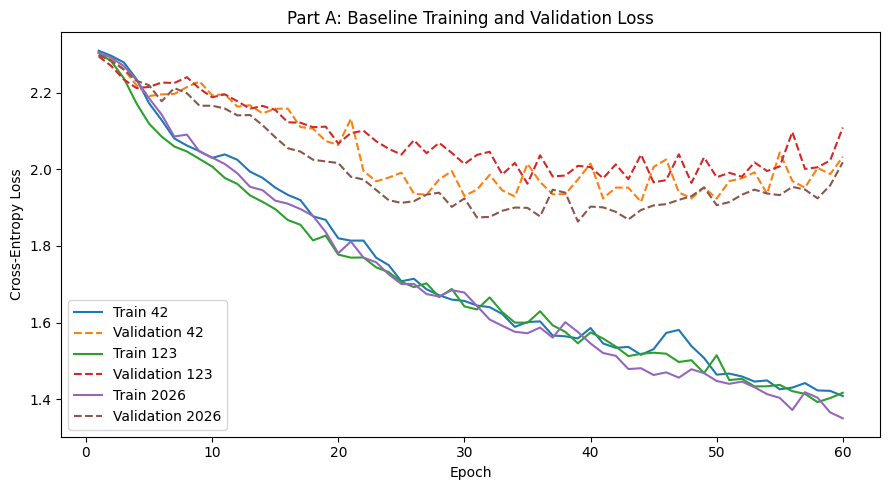

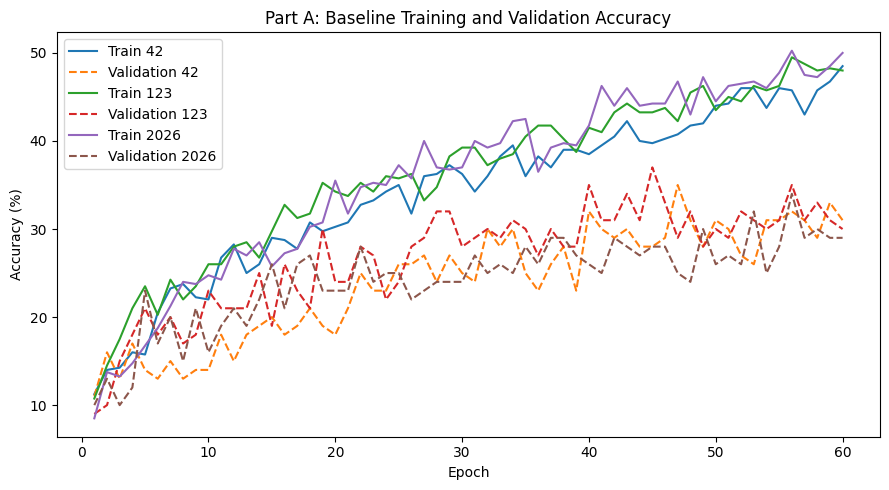

In [28]:
epochs = range(1, EPOCHS + 1)

plt.figure(figsize=(9, 5))
for seed, h in zip(SEEDS, histories):
    plt.plot(epochs, h["train_loss"], label=f"Train {seed}")
    plt.plot(epochs, h["val_loss"], "--", label=f"Validation {seed}")
plt.title("Part A: Baseline Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Cross-Entropy Loss")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
for seed, h in zip(SEEDS, histories):
    plt.plot(epochs, h["train_acc"], label=f"Train {seed}")
    plt.plot(epochs, h["val_acc"], "--", label=f"Validation {seed}")
plt.title("Part A: Baseline Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.tight_layout()
plt.show()

In [29]:
train_loader = DataLoader(train, batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=0)
val_loader = DataLoader(val, batch_size=BATCH_SIZE,
                        shuffle=False, num_workers=0)
clean_loader = DataLoader(clean_test, batch_size=BATCH_SIZE,
                          shuffle=False, num_workers=0)
shifted_loader = DataLoader(shifted_test, batch_size=BATCH_SIZE,
                            shuffle=False, num_workers=0)

results = []

for seed, model in zip(SEEDS, models):
    _, train_acc = evaluate(model, train_loader)
    _, val_acc = evaluate(model, val_loader)
    _, clean_acc = evaluate(model, clean_loader)
    _, shifted_acc = evaluate(model, shifted_loader)

    results.append({
        "Seed": seed,
        "Train Accuracy (%)": train_acc,
        "Validation Accuracy (%)": val_acc,
        "Clean-Test Accuracy (%)": clean_acc,
        "Shifted-Test Accuracy (%)": shifted_acc
    })

print("\nRESULTS — Accuracy for Each Seed")
for r in results:
    print(
        f"Seed {r['Seed']} | "
        f"Train: {r['Train Accuracy (%)']:.2f}% | "
        f"Validation: {r['Validation Accuracy (%)']:.2f}% | "
        f"Clean Test: {r['Clean-Test Accuracy (%)']:.2f}% | "
        f"Shifted Test: {r['Shifted-Test Accuracy (%)']:.2f}%"
    )

print("\nRESULTS — Mean ± Standard Deviation")
for key in [
    "Train Accuracy (%)",
    "Validation Accuracy (%)",
    "Clean-Test Accuracy (%)",
    "Shifted-Test Accuracy (%)"
]:
    values = np.array([r[key] for r in results])
    print(f"{key}: {values.mean():.2f} ± {values.std(ddof=1):.2f}%")

clean_mean = np.mean([r["Clean-Test Accuracy (%)"] for r in results])
shifted_mean = np.mean([r["Shifted-Test Accuracy (%)"] for r in results])
print(f"\nMean clean-to-shifted accuracy gap: {clean_mean - shifted_mean:.2f} percentage points")


RESULTS — Accuracy for Each Seed
Seed 42 | Train: 45.50% | Validation: 35.00% | Clean Test: 35.19% | Shifted Test: 16.08%
Seed 123 | Train: 45.00% | Validation: 37.00% | Clean Test: 35.29% | Shifted Test: 17.27%
Seed 2026 | Train: 50.50% | Validation: 34.00% | Clean Test: 35.06% | Shifted Test: 17.61%

RESULTS — Mean ± Standard Deviation
Train Accuracy (%): 47.00 ± 3.04%
Validation Accuracy (%): 35.33 ± 1.53%
Clean-Test Accuracy (%): 35.18 ± 0.12%
Shifted-Test Accuracy (%): 16.99 ± 0.80%

Mean clean-to-shifted accuracy gap: 18.19 percentage points


The baseline model was trained three times using seeds 42, 123, and 2026. For each run, the best checkpoint was selected based on validation accuracy.

### Results Summary

| Metric | Mean Accuracy ± Standard Deviation |
|---|---:|
| Training Accuracy | 47.00% ± 3.04% |
| Validation Accuracy | 35.33% ± 1.53% |
| Clean-Test Accuracy | 35.18% ± 0.12% |
| Shifted-Test Accuracy | 16.99% ± 0.80% |

### Discussion

The model achieved a mean clean-test accuracy of **35.18%**, compared to **16.99%** on the locally generated shifted test set. This is a decrease of **18.19 percentage points**, showing that the baseline model is sensitive to image corruptions. These results provide a baseline for evaluating the improvements made in subsequent parts.

*Note: The shifted-test results are based on the locally generated corruption set.*

## Part B: Baseline Augmentation Strategy

The following augmentations are used:
- **Random crop with padding:** Adds small shifts in object position.
- **Random rotation (±25°):** Improves robustness to rotated images.
- **Horizontal flip:** Adds variation while preserving most object identities.
- **Color jitter:** Changes brightness, contrast, and saturation to improve robustness to lighting and color changes.

Vertical flipping is not used because upside-down objects are generally unrealistic for CIFAR-10. No augmentation is applied to validation or test images.

In [30]:
import torchvision.transforms as transforms

train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomRotation(25),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(
        brightness=0.2,
        contrast=0.2,
        saturation=0.2
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        (0.4914, 0.4822, 0.4465),
        (0.2470, 0.2435, 0.2616)
    )
])

In [31]:
from torchvision.datasets import CIFAR10
from torch.utils.data import Subset

train_indices = train.indices
val_indices = val.indices

train_base = CIFAR10(
    root=raw_train.root,
    train=True,
    download=False,
    transform=train_transform
)

val_base = CIFAR10(
    root=raw_train.root,
    train=True,
    download=False,
    transform=test_transform
)

train = Subset(train_base, train_indices)
val = Subset(val_base, val_indices)

print("Training images:", len(train))
print("Validation images:", len(val))

Training images: 400
Validation images: 100


In [32]:
# Train the augmented model using the same three seeds

part_b_results = {}

for seed in SEEDS:
    model, history, best_epoch = train_model(seed)
    part_b_results[seed] = {
        "model": model,
        "history": history,
        "best_epoch": best_epoch
    }

    print(f"Seed {seed}: Best epoch = {best_epoch}")

Seed 42 | Epoch 01/60 | Train: 10.00% | Val: 10.00%
Seed 42 | Epoch 02/60 | Train: 11.00% | Val: 10.00%
Seed 42 | Epoch 03/60 | Train: 15.25% | Val: 13.00%
Seed 42 | Epoch 04/60 | Train: 15.50% | Val: 15.00%
Seed 42 | Epoch 05/60 | Train: 19.00% | Val: 16.00%
Seed 42 | Epoch 06/60 | Train: 17.50% | Val: 11.00%
Seed 42 | Epoch 07/60 | Train: 22.50% | Val: 15.00%
Seed 42 | Epoch 08/60 | Train: 22.75% | Val: 18.00%
Seed 42 | Epoch 09/60 | Train: 19.00% | Val: 19.00%
Seed 42 | Epoch 10/60 | Train: 20.00% | Val: 14.00%
Seed 42 | Epoch 11/60 | Train: 22.75% | Val: 18.00%
Seed 42 | Epoch 12/60 | Train: 22.75% | Val: 14.00%
Seed 42 | Epoch 13/60 | Train: 22.25% | Val: 18.00%
Seed 42 | Epoch 14/60 | Train: 23.25% | Val: 18.00%
Seed 42 | Epoch 15/60 | Train: 22.50% | Val: 18.00%
Seed 42 | Epoch 16/60 | Train: 23.25% | Val: 20.00%
Seed 42 | Epoch 17/60 | Train: 23.50% | Val: 18.00%
Seed 42 | Epoch 18/60 | Train: 25.50% | Val: 19.00%
Seed 42 | Epoch 19/60 | Train: 24.75% | Val: 17.00%
Seed 42 | Ep

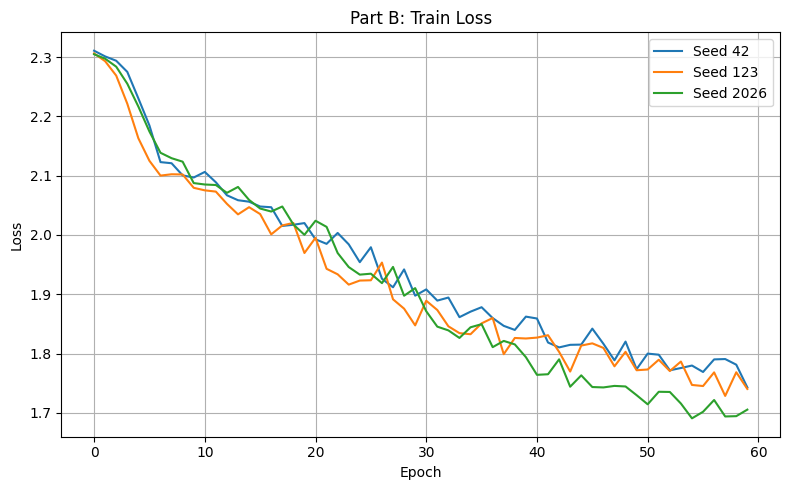

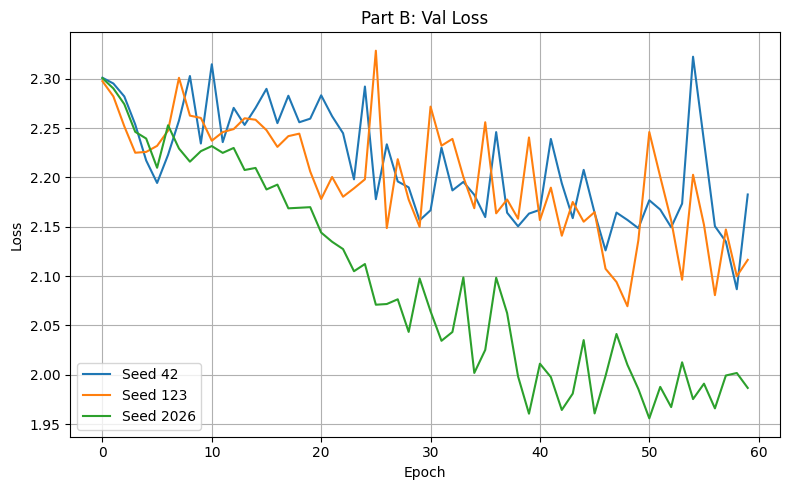

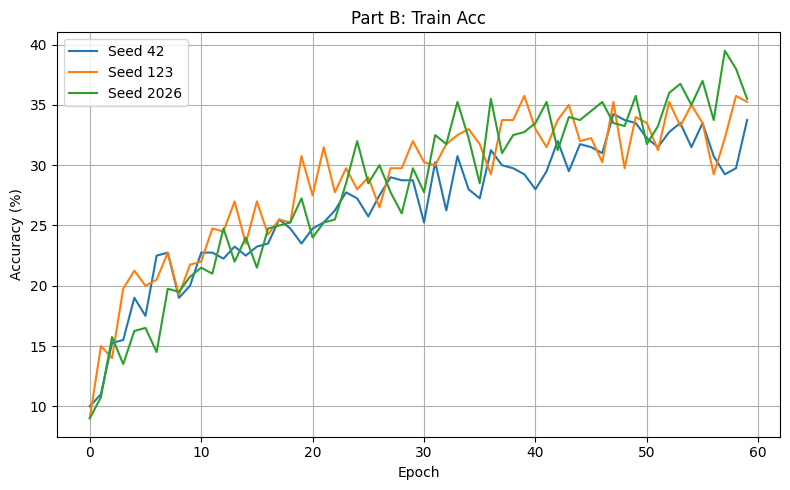

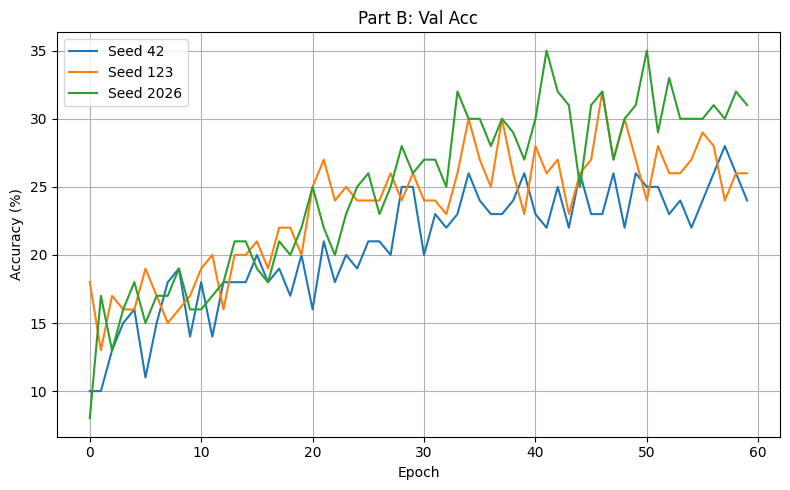

In [33]:
import matplotlib.pyplot as plt

for metric in ["train_loss", "val_loss", "train_acc", "val_acc"]:
    plt.figure(figsize=(8, 5))

    for seed, result in part_b_results.items():
        history = result["history"]
        plt.plot(history[metric], label=f"Seed {seed}")

    plt.title(f"Part B: {metric.replace('_', ' ').title()}")
    plt.xlabel("Epoch")
    plt.ylabel("Loss" if "loss" in metric else "Accuracy (%)")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()

In [34]:
from torch.utils.data import DataLoader
import numpy as np

part_b_scores = {}

for seed, result in part_b_results.items():
    model = result["model"]
    model.eval()

    scores = {}
    for name, dataset in [
        ("Train", train),
        ("Validation", val),
        ("Clean Test", clean_test),
        ("Shifted Test", shifted_test)
    ]:
        loader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=False)
        _, accuracy = evaluate(model, loader)
        scores[name] = accuracy

    part_b_scores[seed] = scores
    print(seed, {k: round(v, 2) for k, v in scores.items()})

print("\nMean ± Standard Deviation")
for name in ["Train", "Validation", "Clean Test", "Shifted Test"]:
    values = [part_b_scores[s][name] for s in SEEDS]
    print(f"{name}: {np.mean(values):.2f}% ± {np.std(values, ddof=1):.2f}%")

42 {'Train': 32.25, 'Validation': 28.0, 'Clean Test': 28.3, 'Shifted Test': 19.89}
123 {'Train': 35.0, 'Validation': 32.0, 'Clean Test': 28.7, 'Shifted Test': 19.55}
2026 {'Train': 35.5, 'Validation': 35.0, 'Clean Test': 29.47, 'Shifted Test': 21.5}

Mean ± Standard Deviation
Train: 34.25% ± 1.75%
Validation: 31.67% ± 3.51%
Clean Test: 28.82% ± 0.59%
Shifted Test: 20.31% ± 1.04%


### Results

The Inception-style CNN was trained using the same architecture and training settings as Part A, with augmentation applied only during training. Three runs were performed using seeds 42, 123, and 2026.

| Metric | Mean Accuracy ± Standard Deviation |
|---|---:|
| Training Accuracy | 34.25% ± 1.75% |
| Validation Accuracy | 31.67% ± 3.51% |
| Clean-Test Accuracy | 28.82% ± 0.59% |
| Shifted-Test Accuracy | 20.31% ± 1.04% |

The shifted-test accuracy was 8.51 percentage points lower than the clean-test accuracy. Compared with Part A, augmentation improved shifted-test accuracy from 16.99% to 20.31%, but reduced clean-test accuracy from 35.18% to 28.82%. This suggests improved robustness to image corruptions at the cost of clean-image performance.

### Questions

**1. Would vertical flip help or hurt on CIFAR-10?**

Vertical flipping would likely hurt because objects such as cars, ships, and animals usually appear upright. Upside-down images may be unrealistic and confuse the model.

**2. What is the trade-off of rotations up to ±90° when the test uses ±25°?**

Larger rotations may improve robustness to extreme orientations but introduce unrealistic training examples. Rotations up to ±25° better match the expected test corruption.

**3. Why can too much augmentation reduce accuracy on a small model?**

Too much augmentation introduces excessive variation, making the learning task harder. A small model has limited capacity to learn these variations, which can lead to underfitting and lower accuracy.

## Part C: Regularization and Training Design

The model uses several techniques to improve generalization and reduce overfitting.

- **Batch Normalization:** Applied after convolutional layers to stabilize activations and support training.
- **Dropout:** Applied before the final fully connected layer to reduce reliance on specific features. It is not placed between early convolutional layers because this could disrupt useful spatial features.
- **Weight Decay:** Applied through the Adam optimizer to discourage excessively large weights.
- **Learning-Rate Scheduling:** ReduceLROnPlateau lowers the learning rate when validation loss stops improving.
- **Early Stopping:** Stops training when validation loss does not improve and restores the best model checkpoint.
- **Label Smoothing:** Softens the target labels to discourage overconfident predictions.

In [41]:
import copy
import random
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

class Inception(nn.Module):
    def __init__(self, ch):
        super().__init__()

        self.branch1 = nn.Sequential(
            nn.Conv2d(ch, 8, kernel_size=1),
            nn.BatchNorm2d(8),
            nn.ReLU()
        )

        self.branch3 = nn.Sequential(
            nn.Conv2d(ch, 8, kernel_size=1),
            nn.BatchNorm2d(8),
            nn.ReLU(),
            nn.Conv2d(8, 8, kernel_size=3, padding=1),
            nn.BatchNorm2d(8),
            nn.ReLU()
        )

        self.branch5 = nn.Sequential(
            nn.Conv2d(ch, 4, kernel_size=1),
            nn.BatchNorm2d(4),
            nn.ReLU(),
            nn.Conv2d(4, 8, kernel_size=5, padding=2),
            nn.BatchNorm2d(8),
            nn.ReLU()
        )

        self.branch_pool = nn.Sequential(
            nn.MaxPool2d(kernel_size=3, stride=1, padding=1),
            nn.Conv2d(ch, 8, kernel_size=1),
            nn.BatchNorm2d(8),
            nn.ReLU()
        )

    def forward(self, x):
        a = self.branch1(x)
        b = self.branch3(x)
        c = self.branch5(x)
        d = self.branch_pool(x)
        return torch.cat([a, b, c, d], dim=1)


class Net(nn.Module):
    def __init__(self):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 24, kernel_size=3, padding=1),
            nn.BatchNorm2d(24),
            nn.ReLU(),
            nn.MaxPool2d(2),

            Inception(24),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 48, kernel_size=3, padding=1),
            nn.BatchNorm2d(48),
            nn.ReLU(),

            nn.AdaptiveAvgPool2d(1)
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(p=0.3),
            nn.Linear(48, 10)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model_check = Net()
print("Trainable parameters:",
      sum(p.numel() for p in model_check.parameters() if p.requires_grad))

Trainable parameters: 17358


In [42]:
def evaluate_c(model, loader, criterion):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0

    with torch.no_grad():
        for images, labels in loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            outputs = model(images)
            loss = criterion(outputs, labels)

            total_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

    return total_loss / total, 100.0 * correct / total


def train_model_c(seed):
    set_seed(seed)

    generator = torch.Generator()
    generator.manual_seed(seed)

    train_loader = DataLoader(
        train,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        num_workers=0
    )

    val_loader = DataLoader(
        val,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    model = Net().to(DEVICE)

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=4
    )

    history = {
        "train_loss": [],
        "train_acc": [],
        "val_loss": [],
        "val_acc": [],
        "lr": []
    }

    best_val_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    patience = 10
    epochs_without_improvement = 0

    for epoch in range(EPOCHS):
        model.train()
        running_loss = 0.0
        correct = 0
        total = 0

        for images, labels in train_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()
            total += labels.size(0)

        train_loss = running_loss / total
        train_acc = 100.0 * correct / total

        val_loss, val_acc = evaluate_c(model, val_loader, criterion)

        scheduler.step(val_loss)

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["lr"].append(optimizer.param_groups[0]["lr"])

        if val_loss < best_val_loss:
            best_val_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        if (epoch + 1) % 5 == 0 or epoch == 0:
            print(
                f"Seed {seed} | Epoch {epoch + 1}/{EPOCHS} | "
                f"Train Acc: {train_acc:.2f}% | "
                f"Val Acc: {val_acc:.2f}% | "
                f"Val Loss: {val_loss:.4f}"
            )

        if epochs_without_improvement >= patience:
            print(f"Early stopping at epoch {epoch + 1}.")
            break

    model.load_state_dict(best_state)
    print(f"Seed {seed}: best epoch = {best_epoch}")

    return model, history, best_epoch

In [43]:
seeds = [42, 123, 2026]

models_c = {}
histories_c = {}
best_epochs_c = {}

for seed in seeds:
    print(f"\nTraining Part C with seed {seed}")
    model, history, best_epoch = train_model_c(seed)

    models_c[seed] = model
    histories_c[seed] = history
    best_epochs_c[seed] = best_epoch

print("\nBest epochs:")
for seed in seeds:
    print(f"Seed {seed}: {best_epochs_c[seed]}")


Training Part C with seed 42
Seed 42 | Epoch 1/60 | Train Acc: 12.50% | Val Acc: 11.00% | Val Loss: 2.2807
Seed 42 | Epoch 5/60 | Train Acc: 26.25% | Val Acc: 24.00% | Val Loss: 2.1590
Seed 42 | Epoch 10/60 | Train Acc: 31.25% | Val Acc: 23.00% | Val Loss: 2.0661
Seed 42 | Epoch 15/60 | Train Acc: 33.50% | Val Acc: 24.00% | Val Loss: 2.0485
Seed 42 | Epoch 20/60 | Train Acc: 31.25% | Val Acc: 28.00% | Val Loss: 2.0157
Seed 42 | Epoch 25/60 | Train Acc: 36.75% | Val Acc: 31.00% | Val Loss: 1.9613
Seed 42 | Epoch 30/60 | Train Acc: 38.25% | Val Acc: 34.00% | Val Loss: 1.9173
Seed 42 | Epoch 35/60 | Train Acc: 40.75% | Val Acc: 33.00% | Val Loss: 1.9194
Seed 42 | Epoch 40/60 | Train Acc: 40.75% | Val Acc: 41.00% | Val Loss: 1.8912
Early stopping at epoch 42.
Seed 42: best epoch = 32

Training Part C with seed 123
Seed 123 | Epoch 1/60 | Train Acc: 14.00% | Val Acc: 15.00% | Val Loss: 2.2797
Seed 123 | Epoch 5/60 | Train Acc: 24.75% | Val Acc: 23.00% | Val Loss: 2.1993
Seed 123 | Epoch 10

In [44]:
clean_loader = DataLoader(
    clean_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

shifted_loader = DataLoader(
    shifted_test, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

test_criterion = nn.CrossEntropyLoss()
results_c = {}

for seed in seeds:
    model = models_c[seed]

    _, clean_acc = evaluate_c(model, clean_loader, test_criterion)
    _, shifted_acc = evaluate_c(model, shifted_loader, test_criterion)

    best_index = best_epochs_c[seed] - 1
    train_acc = histories_c[seed]["train_acc"][best_index]
    val_acc = histories_c[seed]["val_acc"][best_index]

    results_c[seed] = {
        "Training Accuracy": train_acc,
        "Validation Accuracy": val_acc,
        "Clean-Test Accuracy": clean_acc,
        "Shifted-Test Accuracy": shifted_acc
    }

print("\nPart C Results")
print("-" * 80)

for seed, metrics in results_c.items():
    print(f"\nSeed {seed}")
    for metric, accuracy in metrics.items():
        print(f"{metric}: {accuracy:.2f}%")

print("\nMean Accuracy ± Sample Standard Deviation")
for metric in results_c[seeds[0]]:
    values = [results_c[seed][metric] for seed in seeds]
    print(f"{metric}: {np.mean(values):.2f}% ± {np.std(values, ddof=1):.2f}%")


Part C Results
--------------------------------------------------------------------------------

Seed 42
Training Accuracy: 38.00%
Validation Accuracy: 37.00%
Clean-Test Accuracy: 35.66%
Shifted-Test Accuracy: 18.19%

Seed 123
Training Accuracy: 42.50%
Validation Accuracy: 37.00%
Clean-Test Accuracy: 37.00%
Shifted-Test Accuracy: 18.27%

Seed 2026
Training Accuracy: 48.75%
Validation Accuracy: 36.00%
Clean-Test Accuracy: 39.35%
Shifted-Test Accuracy: 19.32%

Mean Accuracy ± Sample Standard Deviation
Training Accuracy: 43.08% ± 5.40%
Validation Accuracy: 36.67% ± 0.58%
Clean-Test Accuracy: 37.34% ± 1.87%
Shifted-Test Accuracy: 18.59% ± 0.63%


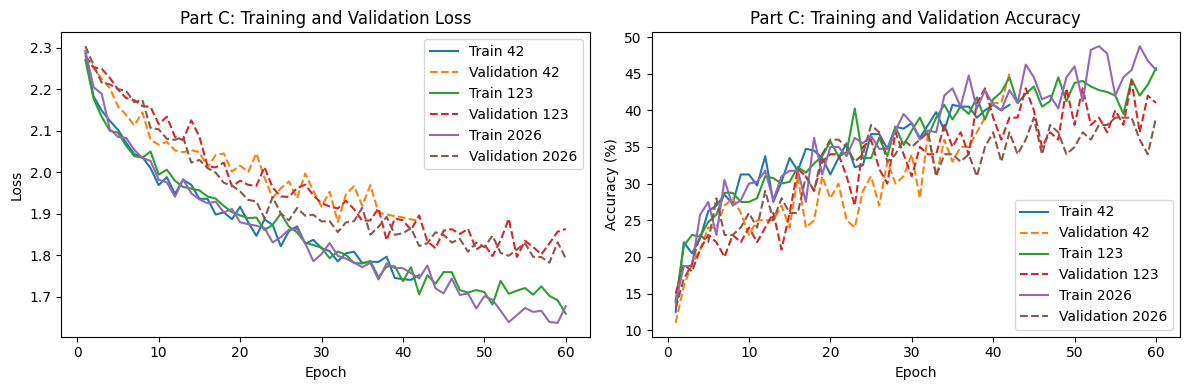

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for seed in seeds:
    history = histories_c[seed]
    epochs = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(epochs, history["train_loss"], label=f"Train {seed}")
    axes[0].plot(epochs, history["val_loss"], linestyle="--",
                 label=f"Validation {seed}")

    axes[1].plot(epochs, history["train_acc"], label=f"Train {seed}")
    axes[1].plot(epochs, history["val_acc"], linestyle="--",
                 label=f"Validation {seed}")

axes[0].set_title("Part C: Training and Validation Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()

axes[1].set_title("Part C: Training and Validation Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy (%)")
axes[1].legend()

plt.tight_layout()
plt.show()

The Inception-style CNN was trained using Batch Normalization, Dropout, weight decay, learning-rate scheduling, early stopping, and label smoothing. Three runs were performed using seeds 42, 123, and 2026. The best checkpoint for each run was selected based on validation loss.

#### Results Summary

| Metric | Mean Accuracy ± Standard Deviation |
|---|---:|
| Training Accuracy | 43.08% ± 5.40% |
| Validation Accuracy | 36.67% ± 0.58% |
| Clean-Test Accuracy | 37.34% ± 1.87% |
| Shifted-Test Accuracy | 18.59% ± 0.63% |

#### Discussion

The model achieved a mean clean-test accuracy of 37.34% and a shifted-test accuracy of 18.59%, a difference of 18.75 percentage points.

Compared with Part B, clean-test accuracy improved from 28.82% to 37.34%, while shifted-test accuracy decreased from 20.31% to 18.59%. This suggests that the regularization techniques improved performance on clean images but did not improve robustness to shifted images.

Validation accuracy showed low variation across the three seeds, with a standard deviation of 0.58 percentage points. Overall, Part C improved clean-test performance, but further tuning may be needed to improve performance on shifted images.

## Part D: Ablation Study

The ablation study evaluates how different augmentation and regularization techniques affect model performance. Each configuration is compared using validation accuracy, clean-test accuracy, and shifted-test accuracy over three random seeds: 42, 123, and 2026.

The configurations include no augmentation, geometric augmentation, photometric augmentation, combined augmentation, Random Erasing, Mixup or CutMix with label smoothing, and the final model. The same data split and evaluation procedure are used for a fair comparison.

The main objective is to identify which configuration performs best on shifted images and understand how its augmentations relate to the corruptions present in the shifted test set.

In [46]:
from torchvision import datasets, transforms
from torch.utils.data import Subset, DataLoader
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import copy
import pandas as pd

MEAN = (0.4914, 0.4822, 0.4465)
STD = (0.2470, 0.2435, 0.2616)


class AddGaussianNoise:
    def __init__(self, std=0.05):
        self.std = std

    def __call__(self, x):
        return torch.clamp(x + torch.randn_like(x) * self.std, -3, 3)


def make_transform(geometric=False, photometric=False, erase=False):
    steps = []

    if geometric:
        steps.extend([
            transforms.RandomCrop(32, padding=4),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomRotation(25)
        ])

    if photometric:
        steps.extend([
            transforms.ColorJitter(
                brightness=0.2,
                contrast=0.2,
                saturation=0.2
            ),
            transforms.GaussianBlur(kernel_size=3, sigma=(0.1, 1.0))
        ])

    steps.extend([
        transforms.ToTensor(),
        transforms.Normalize(MEAN, STD)
    ])

    if photometric:
        steps.append(AddGaussianNoise(std=0.05))

    if erase:
        steps.append(
            transforms.RandomErasing(
                p=0.5,
                scale=(0.02, 0.2),
                ratio=(0.3, 3.3)
            )
        )

    return transforms.Compose(steps)


configs_d = {
    "No augmentation": {
        "geo": False, "photo": False, "erase": False,
        "mixup": False, "smooth": 0.0
    },
    "Geometric only": {
        "geo": True, "photo": False, "erase": False,
        "mixup": False, "smooth": 0.0
    },
    "Photometric only": {
        "geo": False, "photo": True, "erase": False,
        "mixup": False, "smooth": 0.0
    },
    "Geometric + photometric": {
        "geo": True, "photo": True, "erase": False,
        "mixup": False, "smooth": 0.0
    },
    "+ Random Erasing": {
        "geo": True, "photo": True, "erase": True,
        "mixup": False, "smooth": 0.0
    },
    "+ Mixup + label smoothing": {
        "geo": True, "photo": True, "erase": False,
        "mixup": True, "smooth": 0.1
    },
    "Final model": {
        "geo": True, "photo": True, "erase": True,
        "mixup": True, "smooth": 0.1
    }
}

print("Configurations:", len(configs_d))
print("Training samples:", len(train))
print("Validation samples:", len(val))

Configurations: 7
Training samples: 400
Validation samples: 100


In [47]:
def run_ablation(config_name, config, seed):
    set_seed(seed)

    transform = make_transform(
        geometric=config["geo"],
        photometric=config["photo"],
        erase=config["erase"]
    )

    train_base_d = datasets.CIFAR10(
        root=train_base.root,
        train=True,
        download=True,
        transform=transform
    )

    train_subset_d = Subset(train_base_d, train_indices)

    train_loader_d = DataLoader(
        train_subset_d,
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=torch.Generator().manual_seed(seed),
        num_workers=0
    )

    val_loader_d = DataLoader(
        val,
        batch_size=BATCH_SIZE,
        shuffle=False,
        num_workers=0
    )

    model = Net().to(DEVICE)

    criterion = nn.CrossEntropyLoss(
        label_smoothing=config["smooth"]
    )

    optimizer = optim.Adam(
        model.parameters(),
        lr=0.001,
        weight_decay=0.0001
    )

    scheduler = optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=0.5,
        patience=4
    )

    best_loss = float("inf")
    best_state = copy.deepcopy(model.state_dict())
    best_epoch = 0
    wait = 0
    patience = 10

    for epoch in range(EPOCHS):
        model.train()

        for images, labels in train_loader_d:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE)

            optimizer.zero_grad()

            if config["mixup"]:
                lam = np.random.beta(0.2, 0.2)
                index = torch.randperm(images.size(0), device=DEVICE)

                mixed_images = (
                    lam * images + (1 - lam) * images[index]
                )

                outputs = model(mixed_images)

                loss = (
                    lam * criterion(outputs, labels)
                    + (1 - lam) * criterion(outputs, labels[index])
                )
            else:
                outputs = model(images)
                loss = criterion(outputs, labels)

            loss.backward()
            optimizer.step()

        val_loss, val_acc = evaluate_c(
            model, val_loader_d, nn.CrossEntropyLoss()
        )

        scheduler.step(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(model.state_dict())
            best_epoch = epoch + 1
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    model.load_state_dict(best_state)

    _, val_acc = evaluate_c(
        model, val_loader_d, nn.CrossEntropyLoss()
    )
    _, clean_acc = evaluate_c(
        model, clean_loader, nn.CrossEntropyLoss()
    )
    _, shifted_acc = evaluate_c(
        model, shifted_loader, nn.CrossEntropyLoss()
    )

    return {
        "Validation Accuracy": val_acc,
        "Clean Test Accuracy": clean_acc,
        "Shifted Test Accuracy": shifted_acc,
        "Best Epoch": best_epoch
    }


ablation_runs = []

for config_name, config in configs_d.items():
    for seed in [42, 123, 2026]:
        print(f"\nConfiguration: {config_name} | Seed: {seed}")

        result = run_ablation(config_name, config, seed)

        ablation_runs.append({
            "Configuration": config_name,
            "Seed": seed,
            **result
        })

        print(
            f"Val: {result['Validation Accuracy']:.2f}% | "
            f"Clean: {result['Clean Test Accuracy']:.2f}% | "
            f"Shifted: {result['Shifted Test Accuracy']:.2f}% | "
            f"Best epoch: {result['Best Epoch']}"
        )

ablation_df = pd.DataFrame(ablation_runs)


Configuration: No augmentation | Seed: 42
Val: 37.00% | Clean: 40.18% | Shifted: 14.85% | Best epoch: 32

Configuration: No augmentation | Seed: 123
Val: 51.00% | Clean: 41.28% | Shifted: 13.48% | Best epoch: 45

Configuration: No augmentation | Seed: 2026
Val: 39.00% | Clean: 41.38% | Shifted: 13.68% | Best epoch: 44

Configuration: Geometric only | Seed: 42
Val: 44.00% | Clean: 36.07% | Shifted: 17.35% | Best epoch: 39

Configuration: Geometric only | Seed: 123
Val: 40.00% | Clean: 34.91% | Shifted: 18.80% | Best epoch: 55

Configuration: Geometric only | Seed: 2026
Val: 40.00% | Clean: 36.95% | Shifted: 21.12% | Best epoch: 57

Configuration: Photometric only | Seed: 42
Val: 38.00% | Clean: 39.37% | Shifted: 16.02% | Best epoch: 54

Configuration: Photometric only | Seed: 123
Val: 40.00% | Clean: 39.41% | Shifted: 18.36% | Best epoch: 52

Configuration: Photometric only | Seed: 2026
Val: 40.00% | Clean: 39.93% | Shifted: 18.12% | Best epoch: 45

Configuration: Geometric + photometr

In [48]:
metrics_d = [
    "Validation Accuracy",
    "Clean Test Accuracy",
    "Shifted Test Accuracy"
]

summary_d = ablation_df.groupby("Configuration")[metrics_d].agg(
    ["mean", lambda x: x.std(ddof=1)]
)

summary_d.columns = [
    f"{metric} {'Mean' if stat == 'mean' else 'Std'}"
    for metric, stat in summary_d.columns
]

summary_d = summary_d.reindex(list(configs_d.keys()))

print("Part D: Mean Accuracy and Sample Standard Deviation")
for config_name, row in summary_d.iterrows():
    print(f"\n{config_name}")
    for metric in metrics_d:
        mean_value = row[f"{metric} Mean"]
        std_value = row[f"{metric} Std"]
        print(f"{metric}: {mean_value:.2f}% ± {std_value:.2f}%")

print("\nIndividual run results:")
display(ablation_df)

Part D: Mean Accuracy and Sample Standard Deviation

No augmentation
Validation Accuracy: 42.33% ± 7.57%
Clean Test Accuracy: 40.95% ± 0.67%
Shifted Test Accuracy: 14.00% ± 0.74%

Geometric only
Validation Accuracy: 41.33% ± 2.31%
Clean Test Accuracy: 35.98% ± 1.02%
Shifted Test Accuracy: 19.09% ± 1.90%

Photometric only
Validation Accuracy: 39.33% ± 1.15%
Clean Test Accuracy: 39.57% ± 0.31%
Shifted Test Accuracy: 17.50% ± 1.29%

Geometric + photometric
Validation Accuracy: 34.67% ± 4.04%
Clean Test Accuracy: 35.27% ± 1.31%
Shifted Test Accuracy: 21.80% ± 0.77%

+ Random Erasing
Validation Accuracy: 35.00% ± 3.00%
Clean Test Accuracy: 34.49% ± 0.80%
Shifted Test Accuracy: 19.66% ± 1.09%

+ Mixup + label smoothing
Validation Accuracy: 36.33% ± 0.58%
Clean Test Accuracy: 35.50% ± 1.47%
Shifted Test Accuracy: 20.86% ± 2.93%

Final model
Validation Accuracy: 33.67% ± 1.15%
Clean Test Accuracy: 34.43% ± 1.41%
Shifted Test Accuracy: 21.05% ± 1.29%

Individual run results:


,Configuration,Seed,Validation Accuracy,Clean Test Accuracy,Shifted Test Accuracy,Best Epoch
0,No augmentation,42,37.0,40.18,14.85,32
1,No augmentation,123,51.0,41.28,13.48,45
2,No augmentation,2026,39.0,41.38,13.68,44
3,Geometric only,42,44.0,36.07,17.35,39
4,Geometric only,123,40.0,34.91,18.80,55
5,Geometric only,2026,40.0,36.95,21.12,57
6,Photometric only,42,38.0,39.37,16.02,54
7,Photometric only,123,40.0,39.41,18.36,52
8,Photometric only,2026,40.0,39.93,18.12,45
9,Geometric + photometric,42,37.0,35.19,20.91,44


The ablation study evaluates the effect of different augmentation techniques on model performance. Each configuration was tested using three random seeds: 42, 123, and 2026. The results are reported as mean accuracy ± standard deviation.

#### Results

| Configuration | Val Acc | Clean Test | Shifted Test |
|---|---:|---:|---:|
| No augmentation | 42.33% ± 7.57% | 40.95% ± 0.67% | 14.00% ± 0.74% |
| Geometric only (crop, flip, rotation) | 41.33% ± 2.31% | 35.98% ± 1.02% | 19.09% ± 1.90% |
| Photometric only (color jitter, blur, noise) | 39.33% ± 1.15% | 39.57% ± 0.31% | 17.50% ± 1.29% |
| Geometric + photometric | 34.67% ± 4.04% | 35.27% ± 1.31% | 21.80% ± 0.77% |
| + Cutout / Random Erasing | 35.00% ± 3.00% | 34.49% ± 0.80% | 19.66% ± 1.09% |
| + Mixup and label smoothing | 36.33% ± 0.58% | 35.50% ± 1.47% | 20.86% ± 2.93% |
| Final model | 33.67% ± 1.15% | 34.43% ± 1.41% | 21.05% ± 1.29% |

#### Discussion

Geometric + photometric augmentation achieved the highest mean shifted-test accuracy of **21.80%**, improving performance by **7.80 percentage points** compared with no augmentation. Geometric augmentation alone improved accuracy by 5.09 percentage points, while photometric augmentation alone improved it by 3.50 percentage points.

The shifted test includes rotations, brightness and contrast changes, blur, rectangular occlusion, Gaussian noise, and occasional grayscale conversion. Geometric augmentation includes rotations of up to ±25°, matching the rotation range in the shifted test. Photometric augmentation may help the model handle brightness and contrast changes, blur, and noise. However, since the shifted test applies multiple corruptions together, the experiment cannot determine which individual corruption benefited the most.

Adding Random Erasing reduced shifted-test accuracy from 21.80% to 19.66%. Mixup with label smoothing achieved 20.86%, while the final model achieved 21.05%. This shows that adding more techniques did not necessarily improve performance.

No augmentation achieved the highest clean-test accuracy of 40.95%, showing a trade-off between clean-image performance and robustness to shifted images. Overall, combining geometric and photometric augmentation gave the best shifted-test performance among the tested configurations.

## Part E: Error Analysis

This part evaluates the final model's classification errors and its ability to generalize to unseen image corruptions. It includes per-class accuracy, a normalized confusion matrix, analysis of misclassified images, and a hidden-corruption test using pixelation.

The objective is to identify which classes are difficult for the model to classify, understand possible reasons for incorrect predictions, and measure how pixelation affects the model's performance compared with the clean test set.

In [58]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)

class_names = [
    "airplane", "automobile", "bird", "cat", "deer",
    "dog", "frog", "horse", "ship", "truck"
]

print("Device:", DEVICE)
print("Number of test images:", len(test_base))

Device: cuda
Number of test images: 10000


In [59]:
clean_loader = DataLoader(
    test_base,
    batch_size=128,
    shuffle=False
)

final_model.eval()

clean_predictions = []
clean_labels = []

with torch.no_grad():
    for images, labels in clean_loader:
        images = images.to(DEVICE)

        outputs = final_model(images)
        predictions = outputs.argmax(dim=1)

        clean_predictions.extend(predictions.cpu().numpy())
        clean_labels.extend(labels.numpy())

clean_predictions = np.array(clean_predictions)
clean_labels = np.array(clean_labels)

clean_accuracy = 100 * np.mean(clean_predictions == clean_labels)

print(f"Clean Test Accuracy: {clean_accuracy:.2f}%")

Clean Test Accuracy: 39.35%


In [60]:
class_correct = np.zeros(10, dtype=int)
class_total = np.zeros(10, dtype=int)

for true_label, predicted_label in zip(clean_labels, clean_predictions):
    class_total[true_label] += 1

    if true_label == predicted_label:
        class_correct[true_label] += 1

class_accuracy = 100 * class_correct / np.maximum(class_total, 1)

print("Per-Class Accuracy")
print("-" * 35)

for i, name in enumerate(class_names):
    print(
        f"{name:12s}: {class_accuracy[i]:6.2f}% "
        f"({class_correct[i]}/{class_total[i]})"
    )

Per-Class Accuracy
-----------------------------------
airplane    :  29.10% (291/1000)
automobile  :  46.80% (468/1000)
bird        :  20.10% (201/1000)
cat         :  18.60% (186/1000)
deer        :  33.20% (332/1000)
dog         :  44.40% (444/1000)
frog        :  49.50% (495/1000)
horse       :  42.70% (427/1000)
ship        :  66.80% (668/1000)
truck       :  42.30% (423/1000)


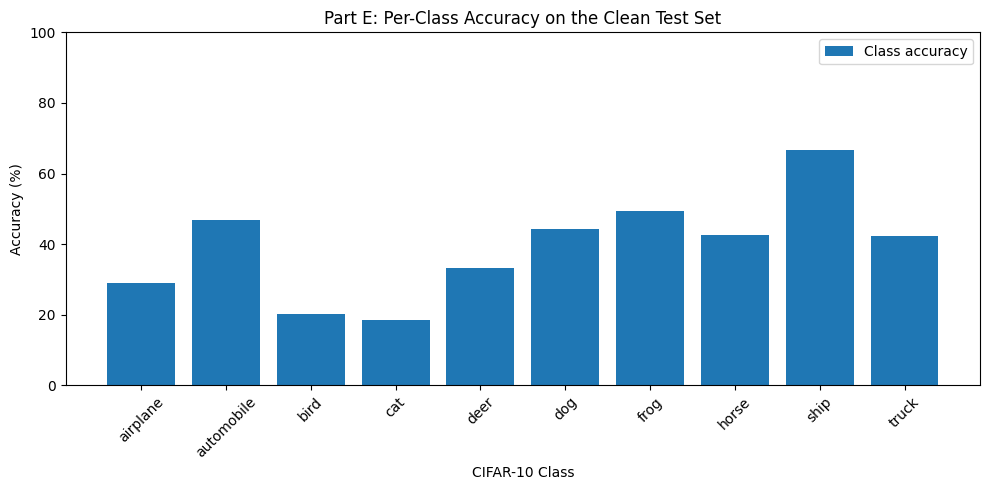

In [61]:
plt.figure(figsize=(10, 5))
plt.bar(class_names, class_accuracy, label="Class accuracy")

plt.title("Part E: Per-Class Accuracy on the Clean Test Set")
plt.xlabel("CIFAR-10 Class")
plt.ylabel("Accuracy (%)")
plt.xticks(rotation=45)
plt.ylim(0, 100)
plt.legend()
plt.tight_layout()
plt.show()

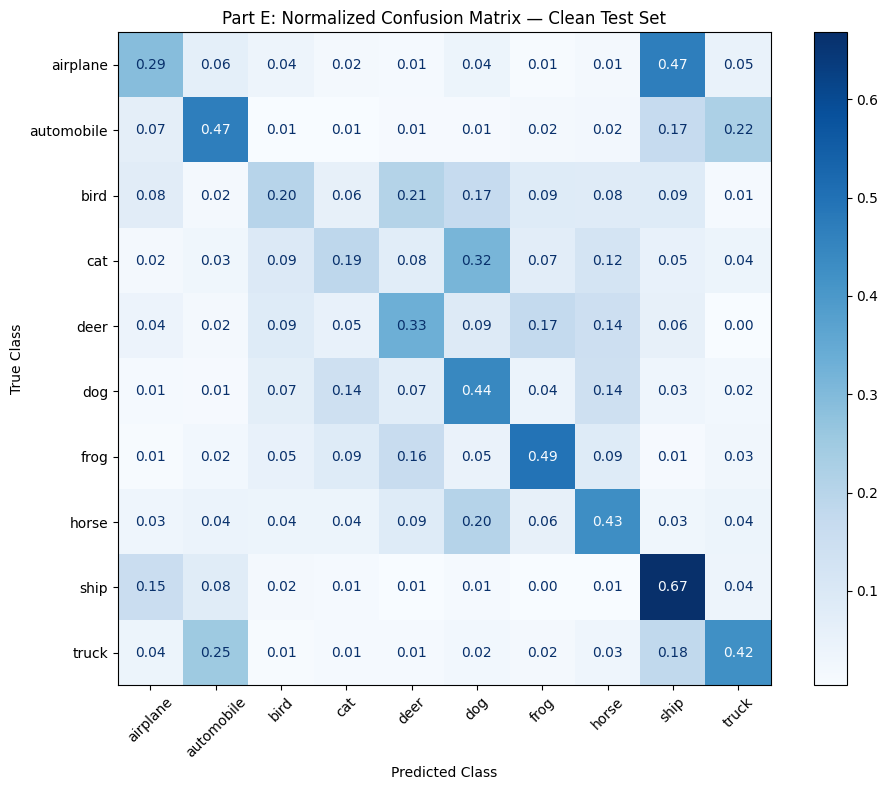

In [62]:
cm = confusion_matrix(
    clean_labels,
    clean_predictions,
    labels=np.arange(10),
    normalize="true"
)

plt.figure(figsize=(10, 8))
display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

display.plot(
    ax=plt.gca(),
    cmap="Blues",
    values_format=".2f",
    colorbar=True
)

plt.title("Part E: Normalized Confusion Matrix — Clean Test Set")
plt.xlabel("Predicted Class")
plt.ylabel("True Class")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
confusion_pairs = []

for true_idx in range(10):
    for pred_idx in range(10):
        if true_idx != pred_idx and cm[true_idx, pred_idx] > 0:
            confusion_pairs.append((
                cm[true_idx, pred_idx],
                class_names[true_idx],
                class_names[pred_idx]
            ))

confusion_pairs.sort(reverse=True)

print("Top 10 Class Confusions")
print("-" * 45)

for proportion, true_name, pred_name in confusion_pairs[:10]:
    print(
        f"True: {true_name:12s} -> Predicted: {pred_name:12s} "
        f"| {proportion * 100:.2f}% of true class"
    )

Top 10 Class Confusions
---------------------------------------------
True: airplane     -> Predicted: ship         | 46.80% of true class
True: cat          -> Predicted: dog          | 31.50% of true class
True: truck        -> Predicted: automobile   | 25.10% of true class
True: automobile   -> Predicted: truck        | 22.40% of true class
True: bird         -> Predicted: deer         | 20.70% of true class
True: horse        -> Predicted: dog          | 20.40% of true class
True: truck        -> Predicted: ship         | 18.00% of true class
True: deer         -> Predicted: frog         | 17.30% of true class
True: bird         -> Predicted: dog          | 16.90% of true class
True: automobile   -> Predicted: ship         | 16.80% of true class


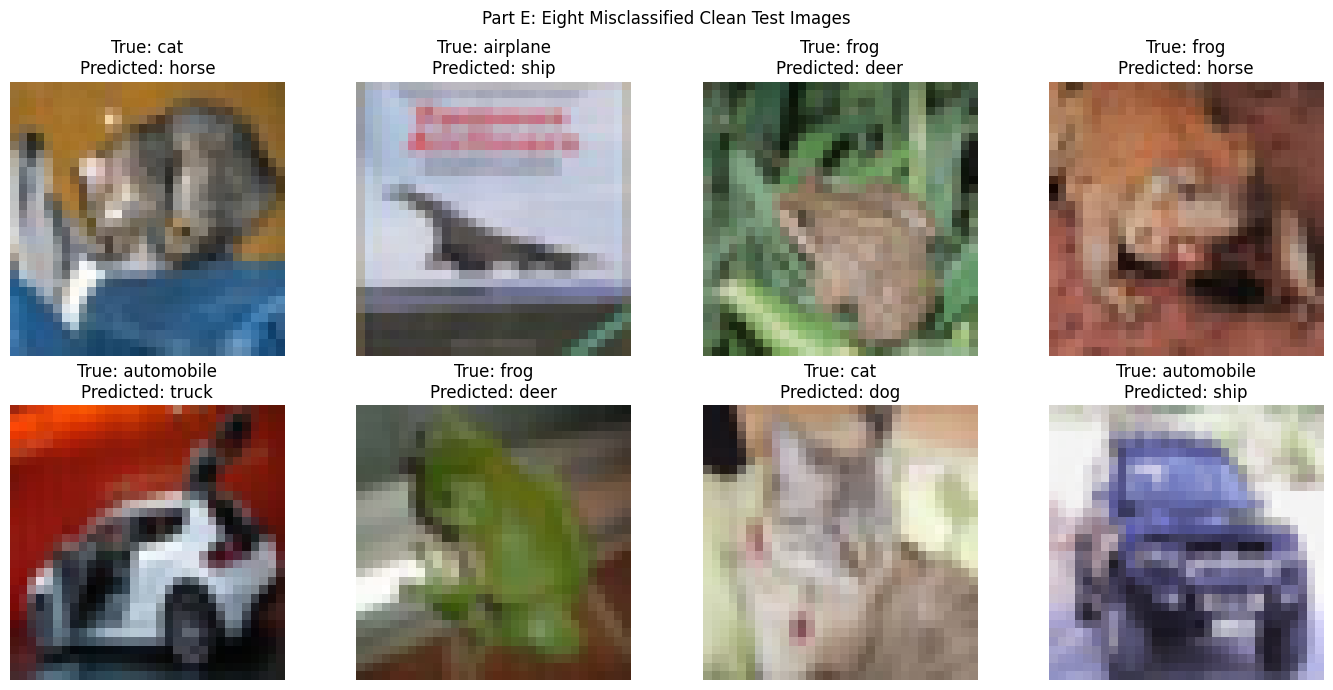

In [64]:
wrong_indices = np.where(clean_predictions != clean_labels)[0]

if len(wrong_indices) < 8:
    print(f"Only {len(wrong_indices)} misclassified images were found.")
    selected_indices = wrong_indices
else:
    selected_indices = wrong_indices[:8]

fig, axes = plt.subplots(2, 4, figsize=(14, 7))
axes = axes.flatten()

for ax in axes:
    ax.axis("off")

for i, idx in enumerate(selected_indices):
    image = Image.fromarray(test_base.data[idx])
    true_label = clean_labels[idx]
    predicted_label = clean_predictions[idx]

    axes[i].imshow(image)
    axes[i].set_title(
        f"True: {class_names[true_label]}\n"
        f"Predicted: {class_names[predicted_label]}"
    )
    axes[i].axis("off")

fig.suptitle("Part E: Eight Misclassified Clean Test Images")
plt.tight_layout()
plt.show()

### Analysis of Misclassified Images

The following table presents eight misclassified CIFAR-10 images and possible visual reasons for the incorrect predictions.

| **Image** | **True Class** | **Predicted Class** | **Possible Visual Reason** |
|---|---|---|---|
| 1 | Cat | Horse | The curled-up posture and curved body lines may resemble the rounded torso and neck profile of a resting horse. |
| 2 | Airplane | Ship | The dark, elongated horizontal shape of the airplane may resemble the hull of a ship. |
| 3 | Frog | Deer | The brownish coloration and textured background may obscure the frog's features, making the image resemble a deer in its natural habitat. |
| 4 | Frog | Horse | The reddish-brown background and viewing angle may make the subject's silhouette resemble part of a horse. |
| 5 | Automobile | Truck | The high-contrast white body and rear structure may resemble the larger body and cargo area of a light truck. |
| 6 | Frog | Deer | The frog's posture and surrounding brownish surface may obscure its shape and create a misleading impression of a standing deer. |
| 7 | Cat | Dog | Similar facial features, lighting, and head shape may make the cat resemble a dog, particularly at low resolution. |
| 8 | Automobile | Ship | The dark, low-light frontal view of the automobile may resemble the bow of a ship because of its heavy, metallic appearance. |

**Discussion:** These errors may occur because CIFAR-10 images have low resolution, making fine details difficult to distinguish. Similar shapes, unclear object boundaries, lighting, and background textures can also confuse the model. The explanations are possible visual interpretations of the errors rather than confirmed causes of the model's predictions.

In [65]:
class PixelatedCIFAR10(Dataset):
    def __init__(self, base_dataset, transform=None, small_size=8):
        self.data = base_dataset.data
        self.targets = base_dataset.targets
        self.transform = transform
        self.small_size = small_size

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        image = Image.fromarray(self.data[index])

        image = image.resize(
            (self.small_size, self.small_size),
            Image.Resampling.BILINEAR
        )

        image = image.resize(
            (32, 32),
            Image.Resampling.NEAREST
        )

        if self.transform is not None:
            image = self.transform(image)

        label = self.targets[index]
        return image, label


pixelated_test = PixelatedCIFAR10(
    base_dataset=test_base,
    transform=test_base.transform,
    small_size=8
)

pixelated_loader = DataLoader(
    pixelated_test,
    batch_size=128,
    shuffle=False
)

print("Pixelated test images:", len(pixelated_test))
print("Pixelation size: 8 x 8, enlarged to 32 x 32")

Pixelated test images: 10000
Pixelation size: 8 x 8, enlarged to 32 x 32


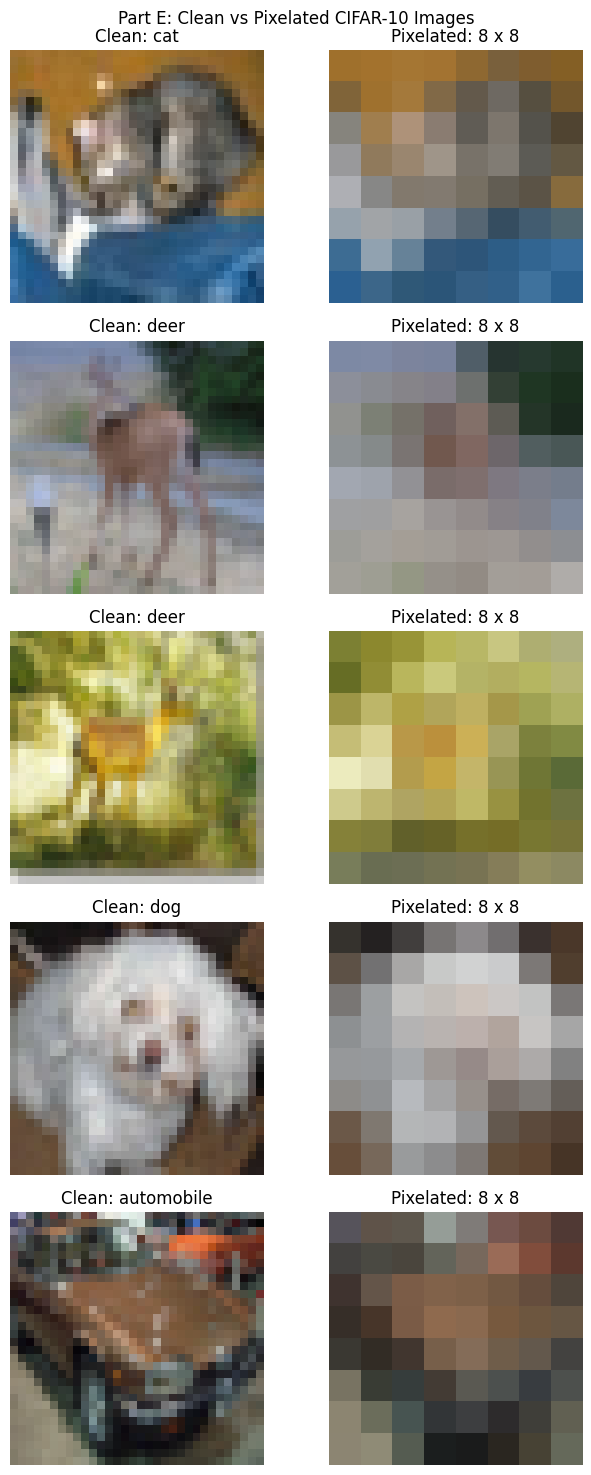

In [66]:
sample_indices = [0, 100, 500, 1000, 2000]

fig, axes = plt.subplots(
    len(sample_indices), 2,
    figsize=(7, 3 * len(sample_indices))
)

for row, idx in enumerate(sample_indices):
    original = Image.fromarray(test_base.data[idx])

    pixelated = original.resize(
        (8, 8),
        Image.Resampling.BILINEAR
    ).resize(
        (32, 32),
        Image.Resampling.NEAREST
    )

    axes[row, 0].imshow(original)
    axes[row, 0].set_title(
        f"Clean: {class_names[test_base.targets[idx]]}"
    )
    axes[row, 0].axis("off")

    axes[row, 1].imshow(pixelated)
    axes[row, 1].set_title("Pixelated: 8 x 8")
    axes[row, 1].axis("off")

fig.suptitle("Part E: Clean vs Pixelated CIFAR-10 Images")
plt.tight_layout()
plt.show()

In [67]:
final_model.eval()

pixelated_predictions = []
pixelated_labels = []

with torch.no_grad():
    for images, labels in pixelated_loader:
        images = images.to(DEVICE)

        outputs = final_model(images)
        predictions = outputs.argmax(dim=1)

        pixelated_predictions.extend(predictions.cpu().numpy())
        pixelated_labels.extend(labels.numpy())

pixelated_predictions = np.array(pixelated_predictions)
pixelated_labels = np.array(pixelated_labels)

pixelated_accuracy = (
    100 * np.mean(pixelated_predictions == pixelated_labels)
)

accuracy_change = pixelated_accuracy - clean_accuracy

print(f"Clean Test Accuracy: {clean_accuracy:.2f}%")
print(f"Pixelated Test Accuracy: {pixelated_accuracy:.2f}%")
print(f"Accuracy Change: {accuracy_change:+.2f} percentage points")

Clean Test Accuracy: 39.35%
Pixelated Test Accuracy: 22.51%
Accuracy Change: -16.84 percentage points


Class           Clean (%)   Pixelated (%)   Change (pp)
-------------------------------------------------------
airplane            29.10           15.10        -14.00
automobile          46.80            1.50        -45.30
bird                20.10           44.80        +24.70
cat                 18.60           30.20        +11.60
deer                33.20           22.10        -11.10
dog                 44.40           11.20        -33.20
frog                49.50            6.40        -43.10
horse               42.70            0.40        -42.30
ship                66.80           84.70        +17.90
truck               42.30            8.70        -33.60


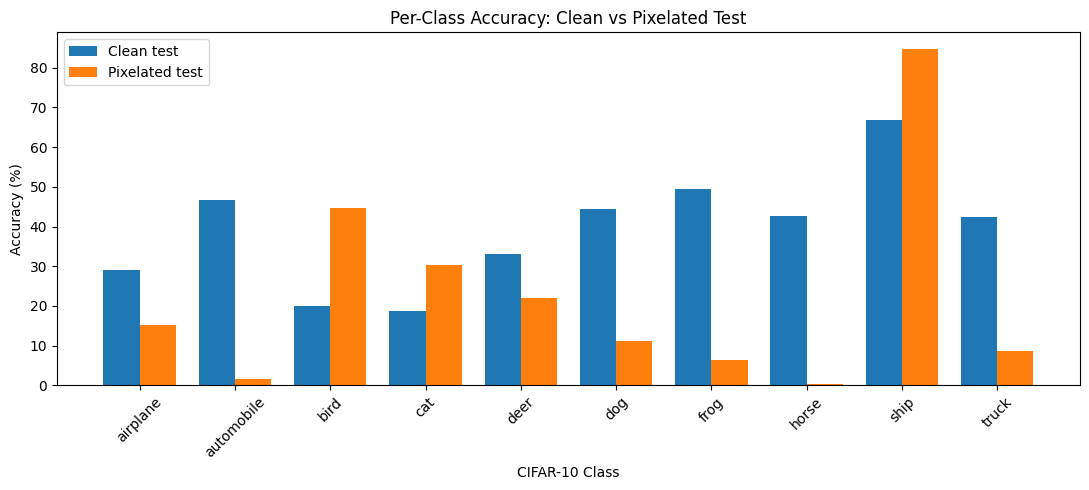

In [68]:
pixelated_class_correct = np.zeros(10, dtype=int)
pixelated_class_total = np.zeros(10, dtype=int)

for true_label, predicted_label in zip(
    pixelated_labels, pixelated_predictions
):
    pixelated_class_total[true_label] += 1

    if true_label == predicted_label:
        pixelated_class_correct[true_label] += 1

pixelated_class_accuracy = (
    100 * pixelated_class_correct /
    np.maximum(pixelated_class_total, 1)
)

print(
    f"{'Class':12s} {'Clean (%)':>12s} "
    f"{'Pixelated (%)':>15s} {'Change (pp)':>13s}"
)
print("-" * 55)

for i, name in enumerate(class_names):
    change = pixelated_class_accuracy[i] - class_accuracy[i]

    print(
        f"{name:12s} {class_accuracy[i]:12.2f} "
        f"{pixelated_class_accuracy[i]:15.2f} "
        f"{change:+13.2f}"
    )

plt.figure(figsize=(11, 5))
x = np.arange(len(class_names))
width = 0.38

plt.bar(
    x - width / 2,
    class_accuracy,
    width,
    label="Clean test"
)
plt.bar(
    x + width / 2,
    pixelated_class_accuracy,
    width,
    label="Pixelated test"
)

plt.title("Per-Class Accuracy: Clean vs Pixelated Test")
plt.xlabel("CIFAR-10 Class")
plt.ylabel("Accuracy (%)")
plt.xticks(x, class_names, rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

### Results

The clean test accuracy was **39.35%**, while the accuracy on the pixelated test set was **22.51%**, resulting in a decrease of **16.84 percentage points**.

The model's augmentation showed limited generalization to pixelation. Although the model was trained with geometric and photometric augmentations, these techniques did not fully prepare it for the loss of fine details caused by downsampling images to 8 × 8 pixels and resizing them back to 32 × 32 pixels.

Pixelation removes important visual features, making objects harder to distinguish, especially between classes with similar shapes. The substantial drop in accuracy indicates that the model remains sensitive to this unseen corruption. Overall, the augmentations improved robustness to some image variations but did not generalize well to pixelation.

## Part F: Test-Time Augmentation

Test-Time Augmentation (TTA) evaluates multiple augmented versions of each test image and averages their softmax probabilities to produce the final prediction. In this experiment, the model uses the original image, horizontal flipping, and small shifts. The objective is to determine whether TTA improves shifted-test accuracy without retraining the model.

In [69]:
import time
import torch
import torch.nn.functional as F
import numpy as np

N_TTA = 6
SHIFT_PIXELS = 2

def create_tta_images(images):
    variants = [images, torch.flip(images, dims=[3])]

    # Shift right, left, down, and up
    shifted = [
        F.pad(images[:, :, :, :-SHIFT_PIXELS], (SHIFT_PIXELS, 0, 0, 0)),
        F.pad(images[:, :, :, SHIFT_PIXELS:], (0, SHIFT_PIXELS, 0, 0)),
        F.pad(images[:, :, :-SHIFT_PIXELS, :], (0, 0, SHIFT_PIXELS, 0)),
        F.pad(images[:, :, SHIFT_PIXELS:, :], (0, 0, 0, SHIFT_PIXELS))
    ]

    variants.extend(shifted)
    return variants

In [71]:
tta_test_loader = shifted_loader

final_model.eval()

normal_predictions = []
tta_predictions = []
true_labels = []

def synchronize_device():
    if DEVICE.type == "cuda":
        torch.cuda.synchronize(DEVICE)

# Normal inference
synchronize_device()
start_time = time.perf_counter()

with torch.no_grad():
    for images, labels in tta_test_loader:
        images = images.to(DEVICE)

        outputs = final_model(images)
        predictions = outputs.argmax(dim=1)

        normal_predictions.extend(predictions.cpu().numpy())
        true_labels.extend(labels.numpy())

synchronize_device()
normal_time = time.perf_counter() - start_time

# TTA inference
synchronize_device()
start_time = time.perf_counter()

with torch.no_grad():
    for images, labels in tta_test_loader:
        images = images.to(DEVICE)

        variants = create_tta_images(images)
        probability_sum = None

        for augmented_images in variants:
            outputs = final_model(augmented_images)
            probabilities = torch.softmax(outputs, dim=1)

            if probability_sum is None:
                probability_sum = probabilities
            else:
                probability_sum += probabilities

        average_probabilities = probability_sum / len(variants)
        predictions = average_probabilities.argmax(dim=1)

        tta_predictions.extend(predictions.cpu().numpy())

synchronize_device()
tta_time = time.perf_counter() - start_time

normal_predictions = np.array(normal_predictions)
tta_predictions = np.array(tta_predictions)
true_labels = np.array(true_labels)

normal_accuracy = 100 * np.mean(normal_predictions == true_labels)
tta_accuracy = 100 * np.mean(tta_predictions == true_labels)

print(f"Normal shifted-test accuracy: {normal_accuracy:.2f}%")
print(f"TTA shifted-test accuracy: {tta_accuracy:.2f}%")
print(f"Accuracy change: {tta_accuracy - normal_accuracy:+.2f} percentage points")
print()
print(f"Normal inference time: {normal_time:.2f} seconds")
print(f"TTA inference time: {tta_time:.2f} seconds")
print(f"Normal time per image: {normal_time / len(true_labels) * 1000:.3f} ms")
print(f"TTA time per image: {tta_time / len(true_labels) * 1000:.3f} ms")
print(f"Inference time multiplier: {tta_time / normal_time:.2f}x")

Normal shifted-test accuracy: 19.32%
TTA shifted-test accuracy: 19.39%
Accuracy change: +0.07 percentage points

Normal inference time: 11.22 seconds
TTA inference time: 12.93 seconds
Normal time per image: 1.122 ms
TTA time per image: 1.293 ms
Inference time multiplier: 1.15x


### Results
The Test-Time Augmentation (TTA) experiment produced the following results:

- **Normal shifted-test accuracy:** 19.32%
- **TTA shifted-test accuracy:** 19.39%
- **Accuracy change:** +0.07 percentage points
- **Normal inference time:** 11.22 seconds
- **TTA inference time:** 12.93 seconds
- **Inference time multiplier:** 1.15×
- **Normal time per image:** 1.122 ms
- **TTA time per image:** 1.293 ms

TTA increased shifted-test accuracy by only 0.07 percentage points, indicating a negligible improvement in robustness. Inference time increased from 11.22 to 12.93 seconds, making TTA approximately 1.15 times slower than normal inference.

Overall, TTA provided very little accuracy improvement compared with its additional computational cost. Therefore, for this model, the tested augmentations did not provide a meaningful improvement in shifted-test performance.